In [1]:
import cv2
from skimage.util import random_noise
import numpy as np
from matplotlib import pyplot as plt

211 180 105


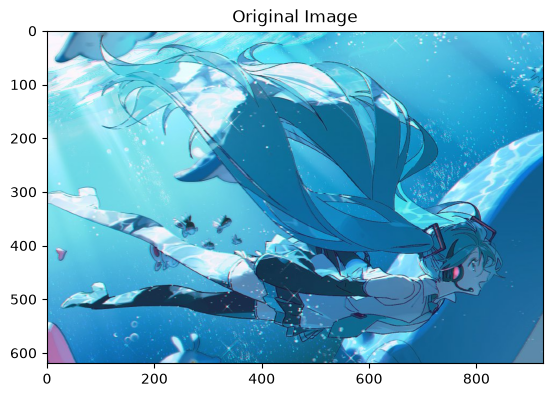

In [8]:
img = cv2.imread('image.png')
rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
(b, g, r) = img[100, 100]
print(b, g, r)
plt.imshow(rgb_img)
plt.title('Original Image')
plt.savefig('output_images/original_bgr.jpg', dpi=300)
plt.show()

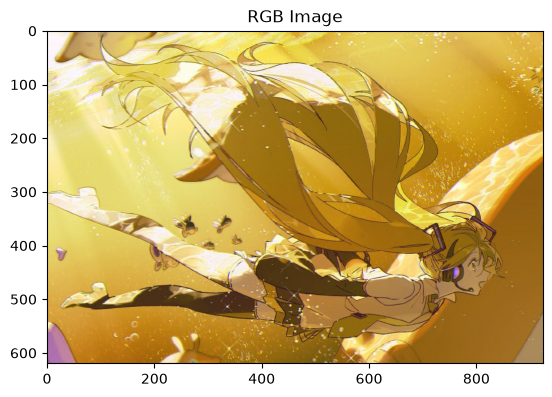

In [9]:
plt.imshow(img)
plt.title('RGB Image')
plt.savefig('output_images/rgb_image.jpg', dpi=300)
plt.show()

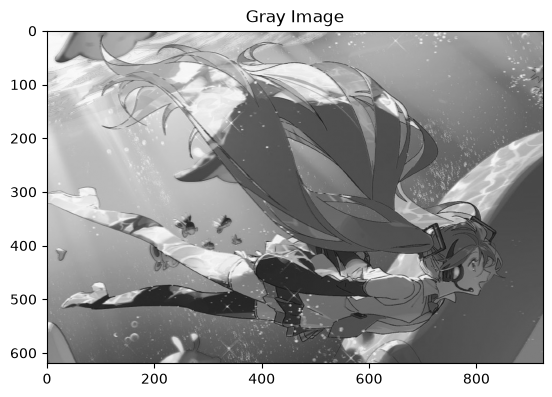

In [10]:
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_img, cmap='gray')
plt.title('Gray Image')
plt.savefig('output_images/gray_image.jpg', dpi=300)
plt.show()

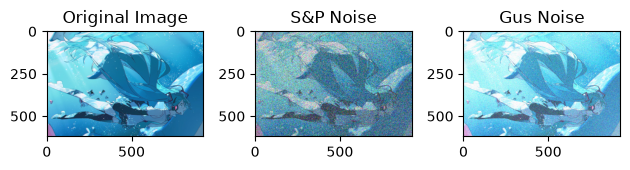

In [11]:
sp_noise_img = random_noise(rgb_img, mode='s&p', amount=0.4)
gus_noise_img = random_noise(rgb_img, mode='gaussian', mean=0.2, var=0.03)

plt.subplot(1, 3, 1)
plt.imshow(rgb_img, cmap='gray')
plt.title('Original Image')

plt.subplot(1, 3, 2)
plt.imshow(sp_noise_img, cmap='gray')
plt.title('S&P Noise')

plt.subplot(1, 3, 3)
plt.imshow(gus_noise_img, cmap='gray')
plt.title('Gus Noise')
plt.tight_layout()
plt.savefig('output_images/noise_comparison.jpg', dpi=300)
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.11927299284620853..1.0000000000000029].


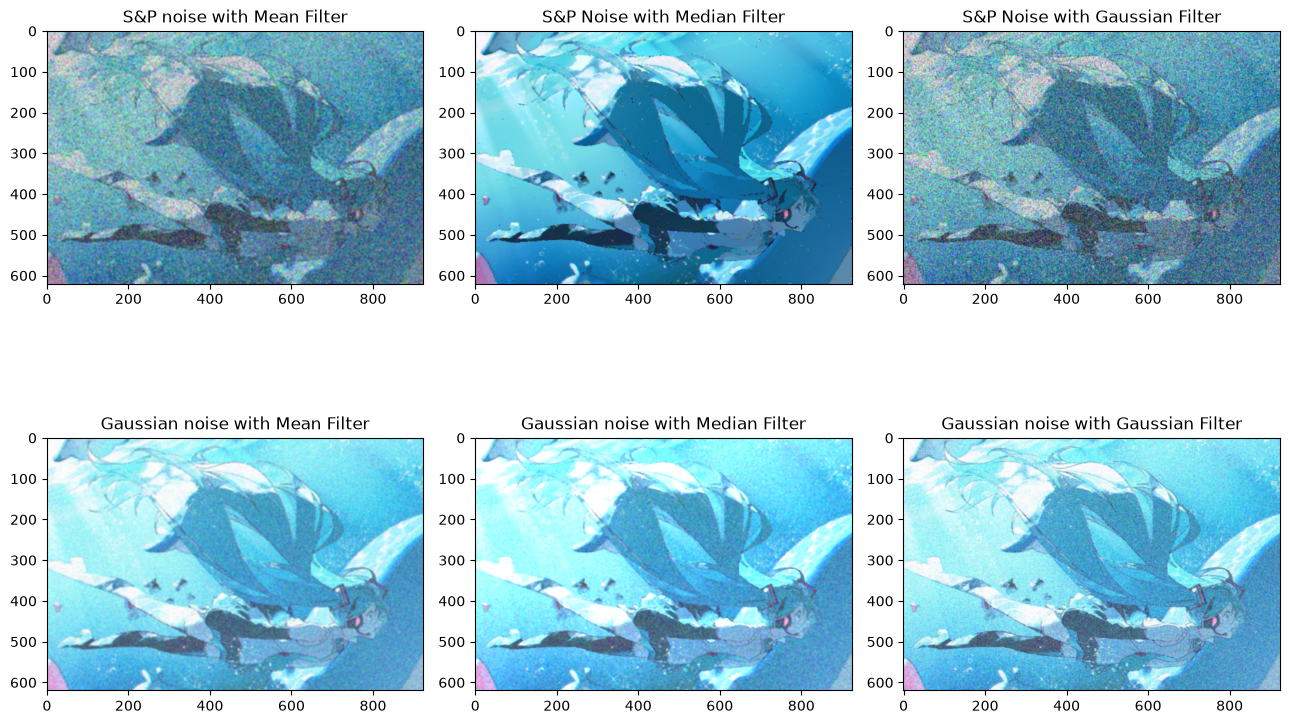

In [12]:
mean_sp = cv2.blur(sp_noise_img, (5, 5))
mean_gus = cv2.blur(gus_noise_img, (5, 5))

mid_sp = cv2.medianBlur((sp_noise_img*255).astype(np.uint8), 5)
mid_gus = cv2.medianBlur((gus_noise_img*255).astype(np.uint8), 5)

gauss_sp = cv2.GaussianBlur((sp_noise_img*255).astype(np.uint8), (5, 5), 0)
gauss_gus = cv2.GaussianBlur((gus_noise_img*255).astype(np.uint8), (5, 5), 0)

plt.figure(figsize=(13, 9))

plt.subplot(2, 3, 1)
plt.imshow(mean_sp)
plt.title("S&P noise with Mean Filter")
plt.subplot(2, 3, 2)
plt.imshow(mid_sp)
plt.title("S&P Noise with Median Filter")
plt.subplot(2, 3, 3)
plt.imshow(gauss_sp)
plt.title("S&P Noise with Gaussian Filter")

plt.subplot(2, 3, 4)
plt.imshow(mean_gus)
plt.title("Gaussian noise with Mean Filter")
plt.subplot(2, 3, 5)
plt.imshow(mid_gus)
plt.title("Gaussian noise with Median Filter")
plt.subplot(2, 3, 6)
plt.imshow(gauss_gus)
plt.title("Gaussian noise with Gaussian Filter")
plt.tight_layout()
plt.savefig('output_images/filter_results_2x3.jpg', dpi=300)
plt.show()

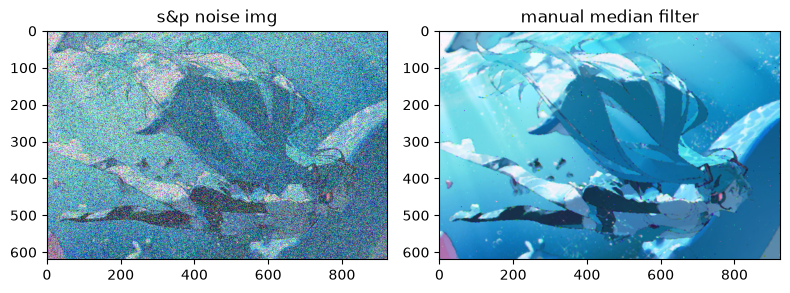

In [13]:
def manual_median_filter_color(image, kernel_size=5):
    pad = kernel_size // 2
    filtered_img = np.zeros_like(image)
    for c in range(3): 
        channel = image[:, :, c]
        padded_channel = np.pad(channel, pad_width=pad, mode='edge')
        for i in range(channel.shape[0]):
            for j in range(channel.shape[1]):
                region = padded_channel[i:i + kernel_size, j:j + kernel_size]
                filtered_img[i, j, c] = np.median(region)
    return filtered_img
    
manual_mid = manual_median_filter_color((sp_noise_img * 255).astype(np.uint8))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(sp_noise_img, cmap='gray')
plt.title("s&p noise img")
plt.subplot(1, 2, 2)
plt.imshow(manual_mid, cmap='gray')
plt.title("manual median filter")
plt.tight_layout()
plt.savefig('output_images/manual_median.jpg', dpi=300)
plt.show()